# Sensibilidad de reservas: incertidumbre de factores con datos CAS

## Pregunta
¿Cuánto cambia la proyección a edad 10 cuando se remuestrean los pares históricos que forman los factores? Este ejercicio mide **solo variación condicional de factores** bajo un bootstrap simple; no estima el error total de reserva ni una distribución predictiva institucional.

**Resultado de este caso:** al cierre de 2007 se estimaron 13.122.496 unidades de pagos adicionales hasta edad 10 frente a 13.458.704 observadas después, con WAPE 2,50 % en nueve cohortes. Son valores históricos en la escala original de CAS, sin factor de cola ni validación de una reserva actual.

## Fuente y corte histórico
Datos de seguro de automóvil de pasajeros de EE. UU., fuente [CAS: NAIC Schedule P compilado para CAS por S&P Global Market Intelligence](https://www.casact.org/publications-research/research/research-resources/loss-reserving-data-pulled-naic-schedule-p). Es obligatorio reconocer CAS/S&P en publicaciones. Años de accidente 1998–2007; se selecciona previamente el grupo State Farm (código 1767), como caso ilustrativo y no representativo. Los montos conservan la escala original del archivo CAS; no se convierten a moneda local.

La fotografía de decisión es 31/12/2007. El desarrollo posterior se mantiene oculto al ajustar factores y se usa solo para comparar pagos acumulados hasta edad 10. Esto no reproduce la reserva contable reportada en 2007: no hay cola más allá de edad 10, gastos adicionales, descuento, reaseguro propio de otra cartera, ni pagos futuros desde hoy. La implementación requiere `pandas`, `numpy`, `matplotlib`, Jupyter y `curl`. La primera ejecución descarga el CSV de CAS; se comprueba SHA-256 y se detiene si cambia el archivo. Los datos externos no se redistribuyen en esta carpeta.

## Datos y diagnóstico

In [1]:
from pathlib import Path
import importlib.util, pandas as pd, numpy as np, matplotlib.pyplot as plt
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'03-financial-risk').is_dir())
project=root/'03-financial-risk/05-enterprise-risk-advisory/06-insurance-climate-esg/insurance-reserving'
spec=importlib.util.spec_from_file_location('cas_chainladder',project/'cas_chainladder.py')
cas=importlib.util.module_from_spec(spec);spec.loader.exec_module(cas)
data,sha=cas.load_data(project/'data/ppauto_pos98-07.csv')
print('Huella fuente:',sha, '| Grupo:',data.GRNAME.iloc[0], '| Filas:',len(data))

Huella fuente: 6e838f1e44c67218133ef1c8e28ca2b34b9f21ba4ee94de408c412638f798d96 | Grupo: State Farm Mut Grp | Filas: 100


In [2]:
assert data.AccidentYear.between(1998,2007).all()
assert set(data.DevelopmentLag)==set(range(1,11))
assert not data.duplicated(['AccidentYear','DevelopmentLag']).any()
triangle=data.pivot(index='AccidentYear',columns='DevelopmentLag',values='CumPaidLoss')
print('Celdas:',triangle.size,'| faltantes:',int(triangle.isna().sum().sum()))
print('Descensos en pagos acumulados entre edades:',int((triangle.diff(axis=1).iloc[:,1:]<0).sum().sum()))
observado=triangle.copy()
for year in observado.index:
    observado.loc[year,[j for j in observado.columns if year+j-1>2007]]=np.nan
print('Triángulo disponible al cierre de 2007:')
observado.round(0)

Celdas: 100 | faltantes: 0
Descensos en pagos acumulados entre edades: 0
Triángulo disponible al cierre de 2007:


DevelopmentLag,1,2,3,4,5,6,7,8,9,10
AccidentYear,,,,,,,,,,
1998,4303375,7133592.0,8477624.0,9255307.0,9654867.0,9834502.0,9924830.0,9972600.0,9995759.0,10012517.0
1999,4435838,7405295.0,8793040.0,9533668.0,9909823.0,10105800.0,10207638.0,10254349.0,10283286.0,NaN
2000,4795841,8101795.0,9465687.0,10207736.0,10632599.0,10829868.0,10928685.0,10981123.0,NaN,NaN
2001,5328657,8821829.0,10242503.0,11064259.0,11503526.0,11720590.0,11837901.0,NaN,NaN,NaN
2002,5859623,9417183.0,10927019.0,11776896.0,12245981.0,12490512.0,NaN,NaN,NaN,NaN
2003,5503855,8822501.0,10228154.0,11082963.0,11561287.0,NaN,NaN,NaN,NaN,NaN
2004,5234002,8449383.0,9834560.0,10710159.0,NaN,NaN,NaN,NaN,NaN,NaN
2005,5168064,8339198.0,9772146.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006,5173526,8386582.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
factors,base=cas.backtest(data,2007)
print('Pares por factor (edades tardías tienen pocas observaciones):')
display(factors)
print('Reserva estimada hasta edad 10:',round(base.reserve_predicted.sum(),2))
print('Pago futuro realizado hasta edad 10:',round(base.future_paid_age10.sum(),2))

Pares por factor (edades tardías tienen pocas observaciones):


,lag,n_pairs,factor
0,1,9,1.634778
1,2,8,1.169196
2,3,7,1.083309
3,4,6,1.041119
4,5,5,1.019176
5,6,4,1.009609
6,7,3,1.004730
7,8,2,1.002576
8,9,1,1.001677


Reserva estimada hasta edad 10: 13122495.99
Pago futuro realizado hasta edad 10: 13458704.0


## Bootstrap de factores: procedimiento y supuestos
Para cada edad, remuestreamos con reemplazo los pares de años visibles en 2007 y calculamos la razón de sumas. Se remuestrean edades de forma independiente (aproximación fuerte), con 1.000 réplicas y semilla 7301. Una edad con un solo par no presenta variabilidad empírica en este procedimiento. No se simulan pagos futuros, dependencia entre edades, cambios de régimen ni cola; el rango 5–95 % es de estimaciones condicionadas, no un intervalo de predicción calibrado.

In [4]:
visible=data.loc[data.calendar_year<=2007].pivot(index='AccidentYear',columns='DevelopmentLag',values='CumPaidLoss')
rng=np.random.default_rng(7301); draws=[]; reps=1000
for rep in range(reps):
    factor_draw={}
    for lag in range(1,10):
        pair=visible.reindex(columns=[lag,lag+1]).dropna()
        idx=rng.integers(0,len(pair),len(pair)); sample=pair.iloc[idx]
        factor_draw[lag]=sample[lag+1].sum()/sample[lag].sum()
    projected=sum(row.paid_to_cutoff*np.prod([factor_draw[k] for k in range(int(row.age),10)])-row.paid_to_cutoff for row in base.itertuples())
    draws.append(projected)
draws=np.asarray(draws); assert len(draws)==reps and np.isfinite(draws).all()
print('P5, mediana, P95 (escala original CAS):',np.quantile(draws,[.05,.5,.95]).round(2))
print('Tasa de pares únicos (edad 9):',int(factors.loc[factors.lag==9,'n_pairs'].iloc[0]))

P5, mediana, P95 (escala original CAS): [12921916.47 13121230.79 13339861.28]
Tasa de pares únicos (edad 9): 1


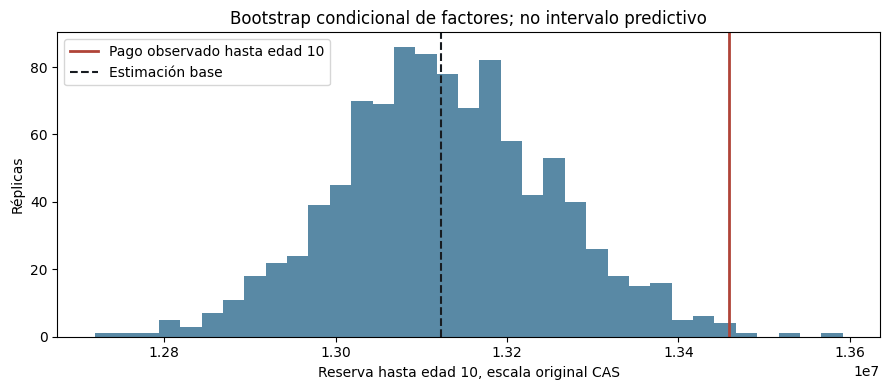

In [5]:
fig,ax=plt.subplots(figsize=(9,4));ax.hist(draws,bins=35,color='#306c8f',alpha=.8)
ax.axvline(base.future_paid_age10.sum(),color='#b04438',label='Pago observado hasta edad 10',linewidth=2)
ax.axvline(base.reserve_predicted.sum(),color='#171b20',linestyle='--',label='Estimación base')
ax.set(title='Bootstrap condicional de factores; no intervalo predictivo',xlabel='Reserva hasta edad 10, escala original CAS',ylabel='Réplicas');ax.legend();plt.tight_layout();plt.show()

## Variante: factores de los tres años más recientes
Se compara con la misma ponderación por volumen, limitando cada edad a los tres pares más recientes disponibles en 2007. En edades con menos de tres pares la variante coincide en esa edad. La elección es una sensibilidad, no una calibración independiente.

In [6]:
recent_f,recent=cas.backtest(data,cutoff=2007,recent=3)
comparison=pd.DataFrame({'todos':[base.reserve_predicted.sum(),base.error.abs().sum()],'tres_recientes':[recent.reserve_predicted.sum(),recent.error.abs().sum()]},index=['reserva_estimada','error_abs_suma'])
display(comparison.round(2)); display(factors.merge(recent_f,on='lag',suffixes=('_todos','_recientes')).round(5))

,todos,tres_recientes
reserva_estimada,13122495.99,12897452.62
error_abs_suma,336208.01,561251.38


,lag,n_pairs_todos,factor_todos,n_pairs_recientes,factor_recientes
0,1,9,1.63478,3,1.61632
1,2,8,1.16920,3,1.16492
2,3,7,1.08331,3,1.08326
3,4,6,1.04112,3,1.04088
4,5,5,1.01918,3,1.01916
5,6,4,1.00961,3,1.00974
6,7,3,1.00473,3,1.00473
7,8,2,1.00258,2,1.00258
8,9,1,1.00168,1,1.00168


## Interpretación y limitaciones
El valor realizado hasta edad 10 permite una comprobación retrospectiva de un único corte, no validar la cobertura del rango bootstrap. No separar error de proceso, parámetros y modelo; no existe garantía de intercambiabilidad de pares ni independencia entre cohortes. Para una decisión real se precisan múltiples cortes verdaderamente disponibles a cada fecha, métodos con error de proceso y validación temporal, siniestros grandes, inflación y juicio actuarial independiente.